<sub>**The Annotated ML Handbook** · Part IV: Visualization</sub>

# Chapter 15: The Matplotlib chart gallery

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-4-visualization/15-viz-mpl-gallery.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 15.1 Set-up for the gallery · *Beginner*

**Shared imports and example data**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales_a = np.array([12, 15, 14, 18, 21, 24])
sales_b = np.array([8, 9, 13, 12, 15, 19])
print(len(months), sales_a.sum(), sales_b.sum())

6 104 76


## 15.2 Charts for change over time · *Beginner*

### 15.2.1 Line plot

**Line plot with markers and a highlighted point**

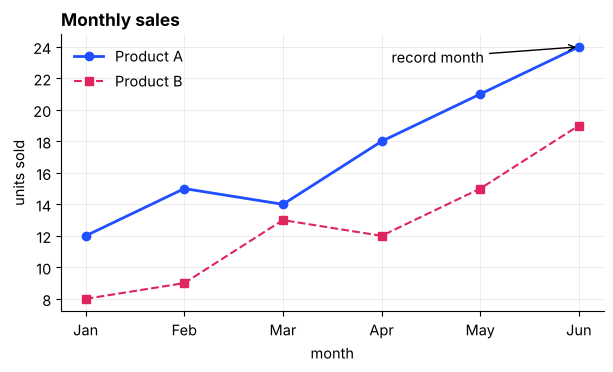

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(months, sales_a, marker="o", lw=2, label="Product A")
ax.plot(months, sales_b, marker="s", ls="--", label="Product B")
ax.annotate("record month", xy=(5, 24), xytext=(3.1, 23),
            arrowprops=dict(arrowstyle="->"))
ax.set(title="Monthly sales", xlabel="month", ylabel="units sold")
ax.legend()
plt.show()

### 15.2.2 Step plot

**A learning-rate schedule as a step plot**

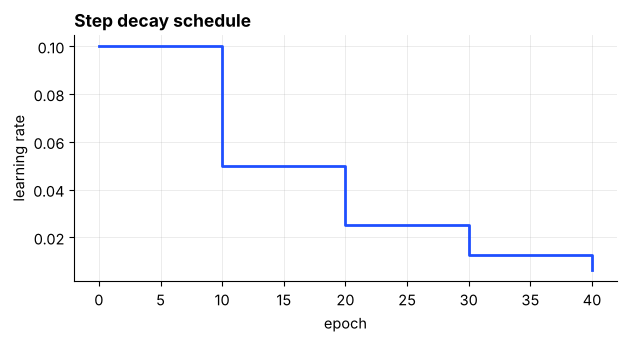

In [4]:
epochs = np.arange(0, 41)
lr = 0.1 * 0.5 ** (epochs // 10)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.step(epochs, lr, where="post", lw=2)
ax.set(title="Step decay schedule", xlabel="epoch", ylabel="learning rate")
plt.show()

### 15.2.3 Area chart and confidence band

**Mean with a ± 1 SD band**

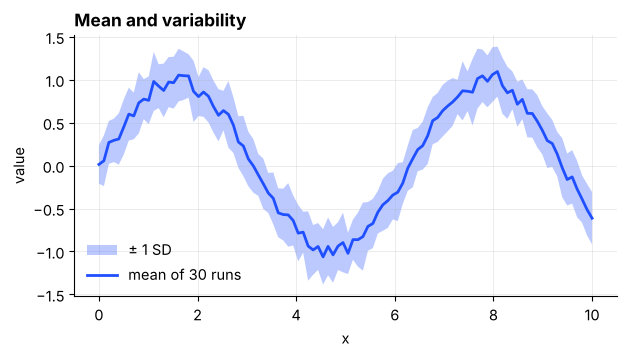

In [5]:
x = np.linspace(0, 10, 100)
runs = np.sin(x) + rng.normal(0, 0.3, size=(30, 100))
mean, sd = runs.mean(axis=0), runs.std(axis=0)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.fill_between(x, mean - sd, mean + sd, alpha=0.3, label="± 1 SD")
ax.plot(x, mean, lw=2, label="mean of 30 runs")
ax.set(title="Mean and variability", xlabel="x", ylabel="value")
ax.legend()
plt.show()

### 15.2.4 Stacked area chart

**Composition over time with stackplot**

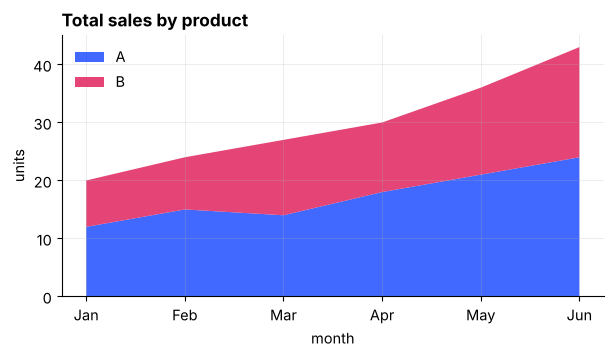

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.stackplot(months, sales_a, sales_b, labels=["A", "B"], alpha=0.85)
ax.set(title="Total sales by product", xlabel="month", ylabel="units")
ax.legend(loc="upper left")
plt.show()

### 15.2.5 Two y-axes (twin axes)

**Rainfall (bars) and temperature (line)**

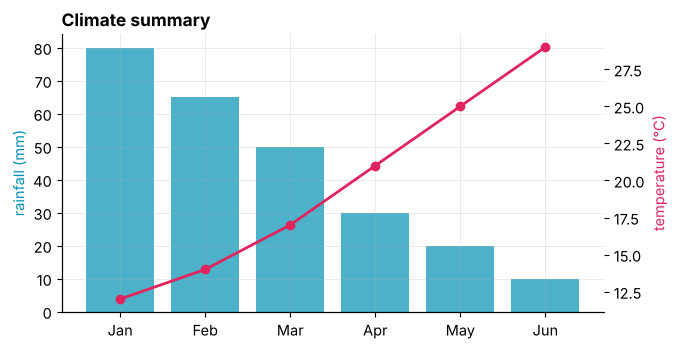

In [7]:
rain = np.array([80, 65, 50, 30, 20, 10])
temp = np.array([12, 14, 17, 21, 25, 29])
fig, ax1 = plt.subplots(figsize=(7, 3.6))
ax1.bar(months, rain, color="#0091b3", alpha=0.7)
ax1.set_ylabel("rainfall (mm)", color="#0091b3")
ax2 = ax1.twinx()
ax2.plot(months, temp, color="#e0245e", marker="o", lw=2)
ax2.set_ylabel("temperature (°C)", color="#e0245e")
ax2.grid(False)
ax1.set_title("Climate summary")
plt.show()

### 15.2.6 Logarithmic axes

**The same data on linear and log axes**

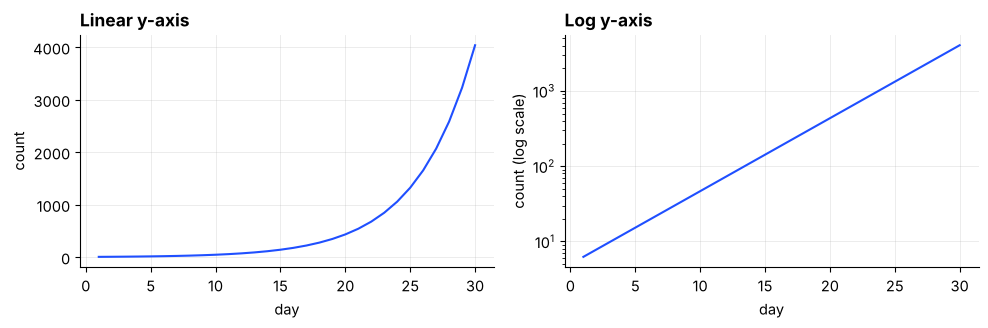

In [8]:
days = np.arange(1, 31)
cases = 5 * 1.25 ** days
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
ax1.plot(days, cases); ax1.set(title="Linear y-axis", xlabel="day", ylabel="count")
ax2.plot(days, cases); ax2.set(title="Log y-axis", xlabel="day", ylabel="count (log scale)", yscale="log")
plt.tight_layout()
plt.show()

## 15.3 Charts for relationships · *Beginner*

### 15.3.1 Scatter and bubble plot

**Scatter with colour and size encoding**

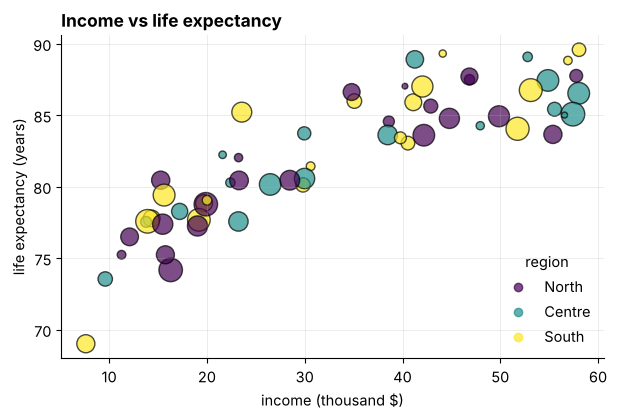

In [9]:
n = 60
income = rng.uniform(5, 60, n)
life = 55 + 8 * np.log(income) + rng.normal(0, 2, n)
region = rng.integers(0, 3, n)
pop = rng.uniform(0.2, 10, n)
fig, ax = plt.subplots(figsize=(7, 4.2))
sc = ax.scatter(income, life, c=region, s=pop * 30, cmap="viridis", alpha=0.7, edgecolor="k")
ax.set(title="Income vs life expectancy", xlabel="income (thousand $)", ylabel="life expectancy (years)")
handles, labels = sc.legend_elements()
ax.legend(handles, ["North", "Centre", "South"], title="region", loc="lower right")
plt.show()

### 15.3.2 2-D histogram and hexbin

**Density of 20,000 points**

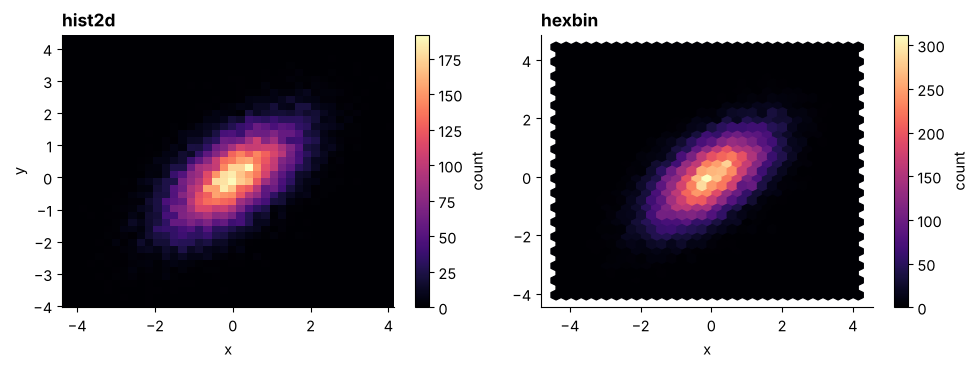

In [10]:
xs = rng.normal(0, 1, 20000)
ys = xs * 0.6 + rng.normal(0, 0.8, 20000)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
h = ax1.hist2d(xs, ys, bins=40, cmap="magma")
fig.colorbar(h[3], ax=ax1, label="count")
ax1.set(title="hist2d", xlabel="x", ylabel="y")
hb = ax2.hexbin(xs, ys, gridsize=30, cmap="magma")
fig.colorbar(hb, ax=ax2, label="count")
ax2.set(title="hexbin", xlabel="x")
for a in (ax1, ax2): a.grid(False)
plt.tight_layout()
plt.show()

### 15.3.3 Contour and filled contour

**A loss surface with contours**

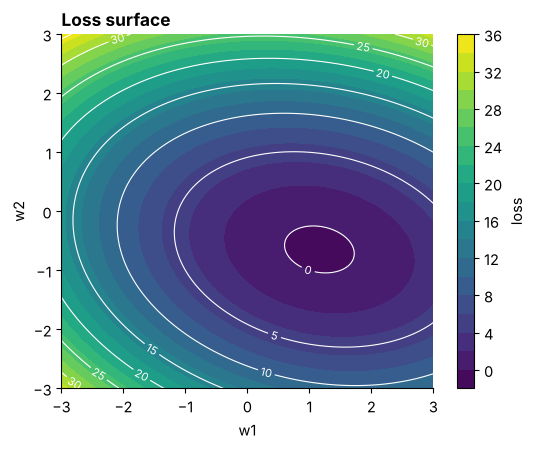

In [11]:
w1, w2 = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
loss = (w1 - 1) ** 2 + 2 * (w2 + 0.5) ** 2 + 0.5 * w1 * w2
fig, ax = plt.subplots(figsize=(6, 4.6))
cf = ax.contourf(w1, w2, loss, levels=20, cmap="viridis")
cs = ax.contour(w1, w2, loss, levels=8, colors="white", linewidths=0.8)
ax.clabel(cs, fontsize=8)
fig.colorbar(cf, label="loss")
ax.set(title="Loss surface", xlabel="w1", ylabel="w2")
ax.grid(False)
plt.show()

## 15.4 Charts for comparing categories · *Beginner*

### 15.4.1 Bar and horizontal bar chart

**Vertical and sorted horizontal bars**

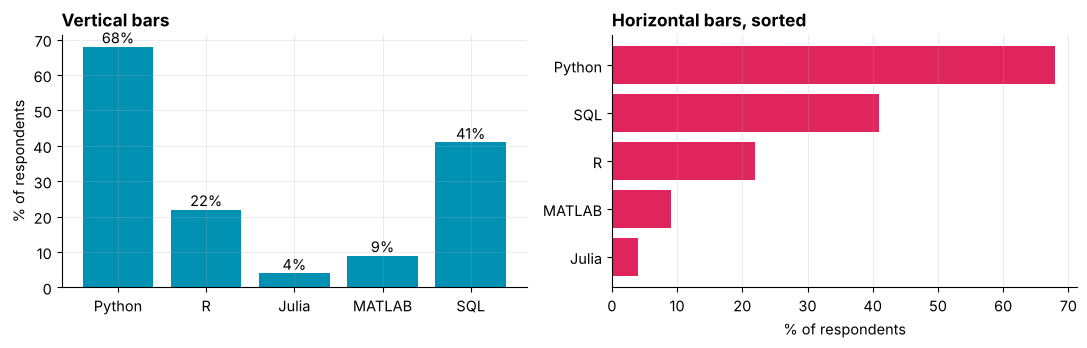

In [12]:
langs = ["Python", "R", "Julia", "MATLAB", "SQL"]
users = np.array([68, 22, 4, 9, 41])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
bars = ax1.bar(langs, users, color="#0091b3")
ax1.bar_label(bars, fmt="%d%%")
ax1.set(title="Vertical bars", ylabel="% of respondents")
order = np.argsort(users)
ax2.barh(np.array(langs)[order], users[order], color="#e0245e")
ax2.set(title="Horizontal bars, sorted", xlabel="% of respondents")
ax2.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 15.4.2 Grouped and stacked bar charts

**Grouped vs stacked**

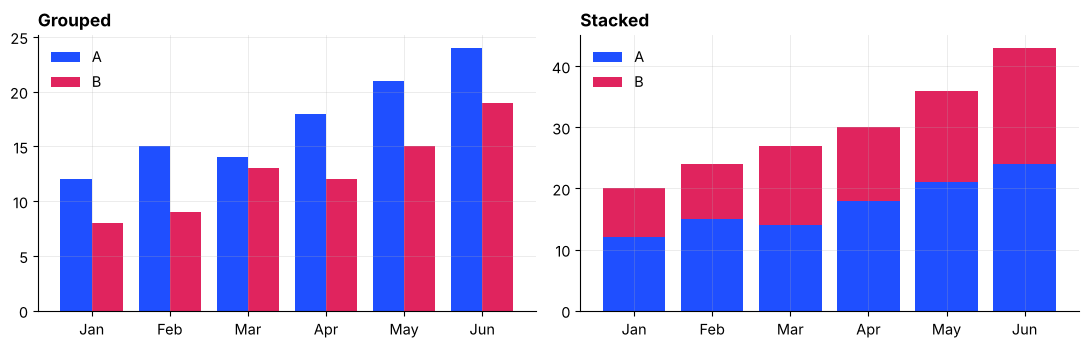

In [13]:
x = np.arange(len(months))
w = 0.4
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.bar(x - w / 2, sales_a, w, label="A")
ax1.bar(x + w / 2, sales_b, w, label="B")
ax1.set(xticks=x, xticklabels=months, title="Grouped")
ax1.legend()
ax2.bar(months, sales_a, label="A")
ax2.bar(months, sales_b, bottom=sales_a, label="B")
ax2.set(title="Stacked")
ax2.legend()
plt.tight_layout()
plt.show()

### 15.4.3 Lollipop chart

**A lollipop chart with stem()**

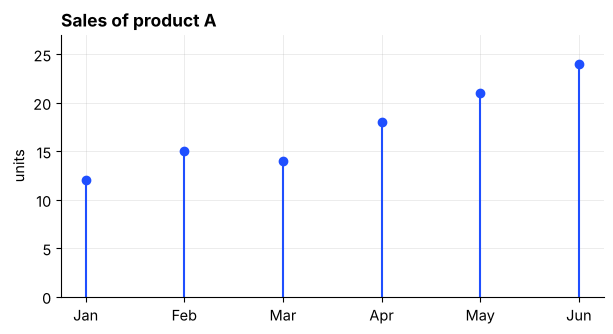

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.stem(months, sales_a, basefmt=" ")
ax.set(title="Sales of product A", ylabel="units", ylim=(0, 27))
plt.show()

### 15.4.4 Pie and donut chart

**Pie and donut**

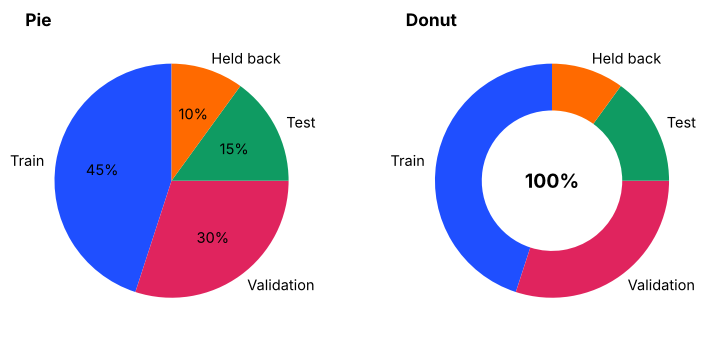

In [15]:
shares = [45, 30, 15, 10]
names = ["Train", "Validation", "Test", "Held back"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))
ax1.pie(shares, labels=names, autopct="%1.0f%%", startangle=90)
ax1.set_title("Pie")
ax2.pie(shares, labels=names, startangle=90, wedgeprops=dict(width=0.4))
ax2.text(0, 0, "100%", ha="center", va="center", fontsize=14, fontweight="bold")
ax2.set_title("Donut")
plt.show()

## 15.5 Charts for distributions · *Beginner*

### 15.5.1 Histogram

**Bins change the story**

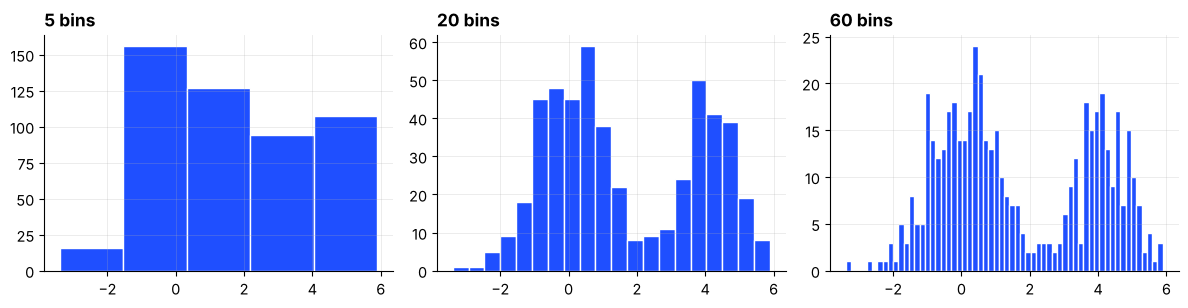

In [16]:
data = np.r_[rng.normal(0, 1, 300), rng.normal(4, 0.8, 200)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=False)
for ax, bins in zip(axes, [5, 20, 60]):
    ax.hist(data, bins=bins, edgecolor="white")
    ax.set_title(f"{bins} bins")
plt.tight_layout()
plt.show()

### 15.5.2 ECDF (empirical cumulative distribution)

**Comparing two groups with ECDFs**

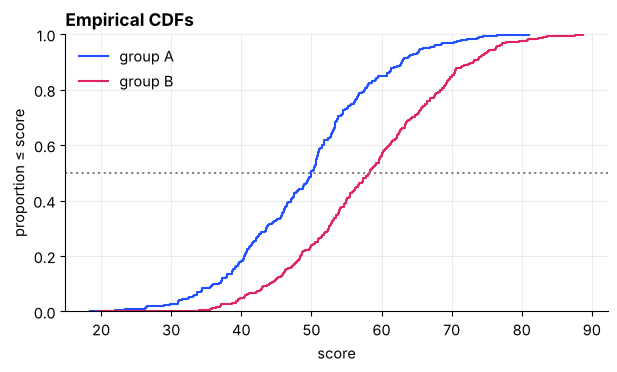

In [17]:
g1, g2 = rng.normal(50, 10, 300), rng.normal(58, 12, 300)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.ecdf(g1, label="group A")
ax.ecdf(g2, label="group B")
ax.axhline(0.5, ls=":", color="grey")
ax.set(title="Empirical CDFs", xlabel="score", ylabel="proportion ≤ score")
ax.legend()
plt.show()

### 15.5.3 Box plot

**Annotated box plot**

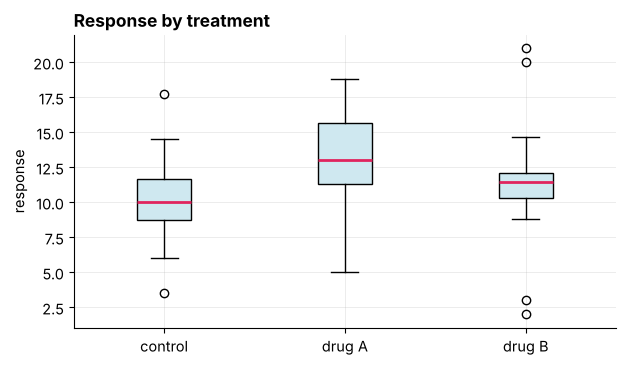

In [18]:
groups = [rng.normal(10, 2, 80), rng.normal(13, 3, 80), np.r_[rng.normal(11, 1.5, 76), [20, 21, 3, 2]]]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.boxplot(groups, tick_labels=["control", "drug A", "drug B"], patch_artist=True,
           boxprops=dict(facecolor="#cfe8f0"), medianprops=dict(color="#e0245e", lw=2))
ax.set(title="Response by treatment", ylabel="response")
plt.show()

### 15.5.4 Violin plot

**Violins reveal hidden structure**

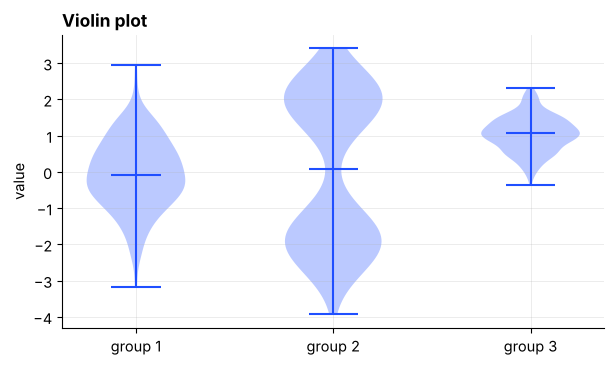

In [19]:
vio = [rng.normal(0, 1, 300), np.r_[rng.normal(-2, 0.6, 150), rng.normal(2, 0.6, 150)], rng.normal(1, 0.5, 300)]
fig, ax = plt.subplots(figsize=(7, 3.8))
parts = ax.violinplot(vio, showmedians=True)
ax.set(xticks=[1, 2, 3], xticklabels=["group 1", "group 2", "group 3"], title="Violin plot", ylabel="value")
plt.show()

## 15.6 Charts for uncertainty · *Intermediate*

### 15.6.1 Error bars

**Means with 95% confidence intervals**

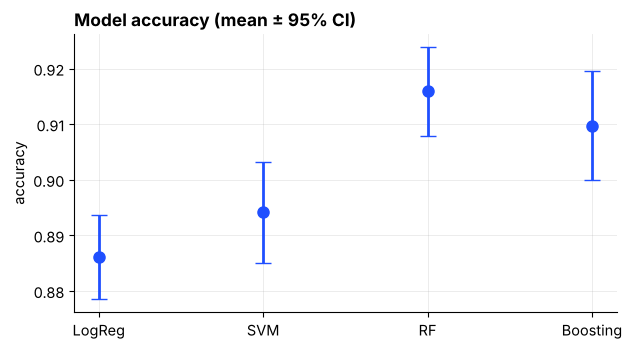

In [20]:
models = ["LogReg", "SVM", "RF", "Boosting"]
acc = [rng.normal(m, 0.015, 10) for m in (0.88, 0.90, 0.91, 0.915)]
means = [a.mean() for a in acc]
ci = [1.96 * a.std(ddof=1) / np.sqrt(len(a)) for a in acc]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(models, means, yerr=ci, fmt="o", capsize=6, ms=8, lw=2)
ax.set(title="Model accuracy (mean ± 95% CI)", ylabel="accuracy")
plt.show()

## 15.7 Charts for matrices and grids · *Intermediate*

### 15.7.1 Heatmap

**Annotated heatmap with imshow**

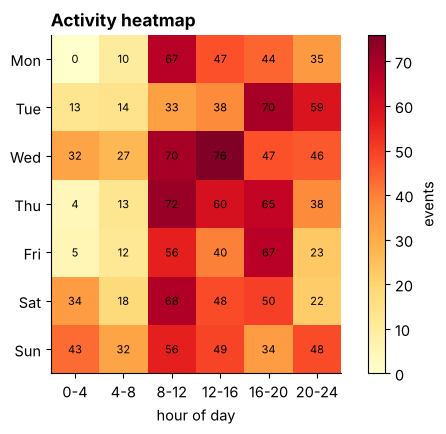

In [21]:
days_ = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
blocks = ["0-4", "4-8", "8-12", "12-16", "16-20", "20-24"]
vals = rng.integers(0, 50, (7, 6)) + np.array([0, 5, 30, 35, 25, 10])
fig, ax = plt.subplots(figsize=(7, 4.4))
im = ax.imshow(vals, cmap="YlOrRd")
ax.set(xticks=range(6), xticklabels=blocks, yticks=range(7), yticklabels=days_,
       xlabel="hour of day", title="Activity heatmap")
for i in range(7):
    for j in range(6):
        ax.text(j, i, vals[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(im, label="events")
ax.grid(False)
plt.show()

### 15.7.2 3-D surface and 3-D scatter

**Surface and scatter in 3-D**

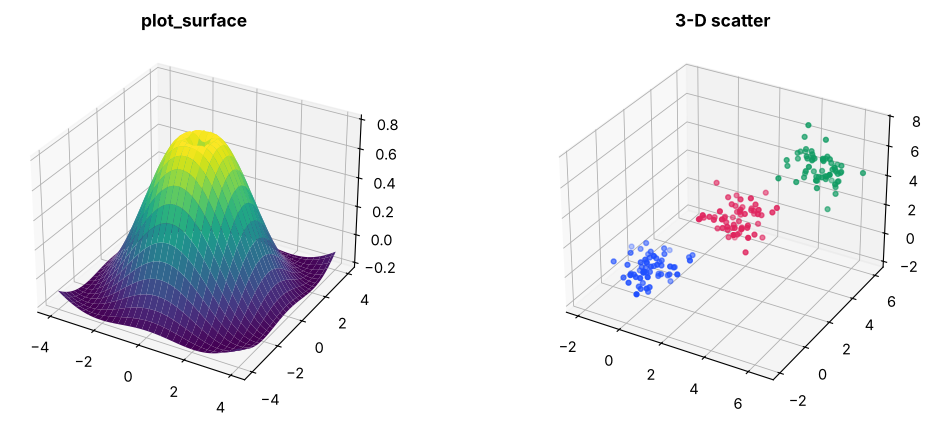

In [22]:
fig = plt.figure(figsize=(11, 4.4))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
X3, Y3 = np.meshgrid(np.linspace(-4, 4, 60), np.linspace(-4, 4, 60))
R = np.sqrt(X3 ** 2 + Y3 ** 2)
ax1.plot_surface(X3, Y3, np.sin(R) / (R + 0.1), cmap="viridis", linewidth=0)
ax1.set_title("plot_surface")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
for k, c in enumerate(["#1f4fff", "#e0245e", "#0f9b62"]):
    pts = rng.normal(k * 2.5, 0.7, (60, 3))
    ax2.scatter(pts[:, 0], pts[:, 1], pts[:, 2], color=c, s=12)
ax2.set_title("3-D scatter")
plt.tight_layout()
plt.show()

## 15.8 Charts for direction, cycles and schedules · *Advanced*

### 15.8.1 Quiver and streamplot

**A vector field two ways**

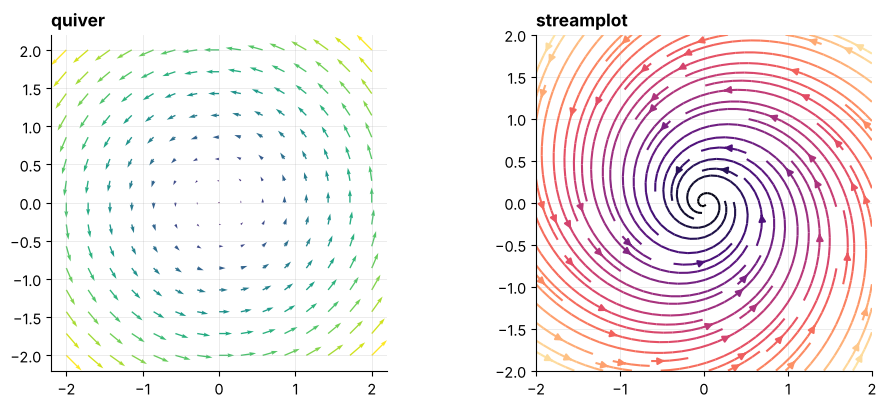

In [23]:
gx, gy = np.meshgrid(np.linspace(-2, 2, 15), np.linspace(-2, 2, 15))
u, v = -gy, gx
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
ax1.quiver(gx, gy, u, v, np.hypot(u, v), cmap="viridis")
ax1.set(title="quiver", aspect="equal")
fx, fy = np.meshgrid(np.linspace(-2, 2, 100), np.linspace(-2, 2, 100))
fu, fv = -fy - 0.3 * fx, fx - 0.3 * fy
ax2.streamplot(fx, fy, fu, fv, color=np.hypot(fu, fv), cmap="magma", density=1.2)
ax2.set(title="streamplot", aspect="equal")
plt.tight_layout()
plt.show()

### 15.8.2 Polar plot and radar chart

**Polar bars and a radar chart**

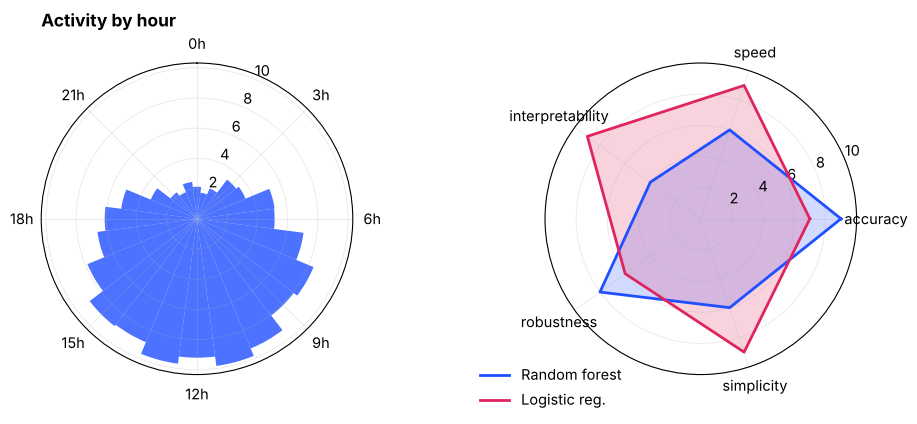

In [24]:
fig = plt.figure(figsize=(10, 4.4))
axp = fig.add_subplot(1, 2, 1, projection="polar")
hours = np.linspace(0, 2 * np.pi, 24, endpoint=False)
activity = 5 + 4 * np.sin(hours - np.pi / 2) + rng.uniform(0, 1.5, 24)
axp.bar(hours, activity, width=2 * np.pi / 24, alpha=0.8)
axp.set_theta_zero_location("N"); axp.set_theta_direction(-1)
axp.set_xticks(hours[::3], [f"{h}h" for h in range(0, 24, 3)])
axp.set_title("Activity by hour")
crit = ["accuracy", "speed", "interpretability", "robustness", "simplicity"]
ang = np.linspace(0, 2 * np.pi, len(crit), endpoint=False).tolist()
axr = fig.add_subplot(1, 2, 2, projection="polar")
for name, sc_ in [("Random forest", [9, 6, 4, 8, 6]), ("Logistic reg.", [7, 9, 9, 6, 9])]:
    vals_ = sc_ + sc_[:1]
    axr.plot(ang + ang[:1], vals_, lw=2, label=name)
    axr.fill(ang + ang[:1], vals_, alpha=0.2)
axr.set_xticks(ang, crit)
axr.set_ylim(0, 10)
axr.legend(loc="lower left", bbox_to_anchor=(-0.25, -0.15))
plt.tight_layout()
plt.show()

### 15.8.3 Gantt chart (timeline) and event plot

**A research project timeline and an event raster**

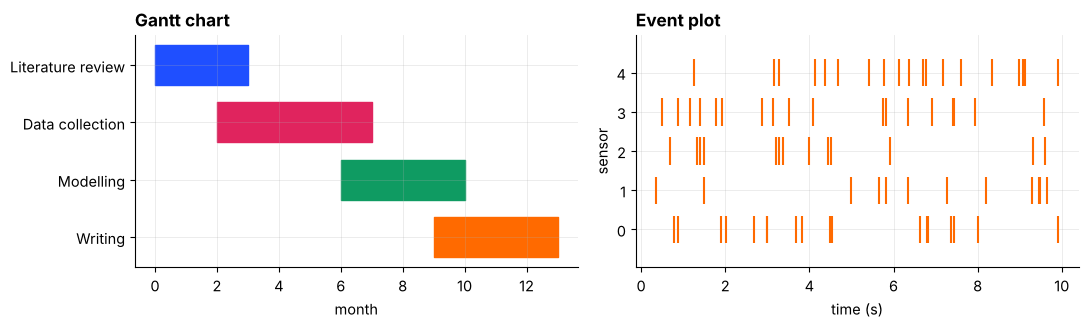

In [25]:
tasks = [("Literature review", 0, 3), ("Data collection", 2, 5), ("Modelling", 6, 4), ("Writing", 9, 4)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
for i, (name, start, dur) in enumerate(tasks):
    ax1.broken_barh([(start, dur)], (i - 0.35, 0.7), color=f"C{i}")
ax1.set(yticks=range(len(tasks)), yticklabels=[t[0] for t in tasks], xlabel="month", title="Gantt chart")
ax1.invert_yaxis()
events = [np.sort(rng.uniform(0, 10, rng.integers(5, 25))) for _ in range(5)]
ax2.eventplot(events, colors="#ff6a00", lineoffsets=range(5), linelengths=0.7)
ax2.set(xlabel="time (s)", ylabel="sensor", title="Event plot")
plt.tight_layout()
plt.show()

## 15.9 Combining charts: layouts, insets and annotations · *Intermediate*

**A dashboard-style figure**

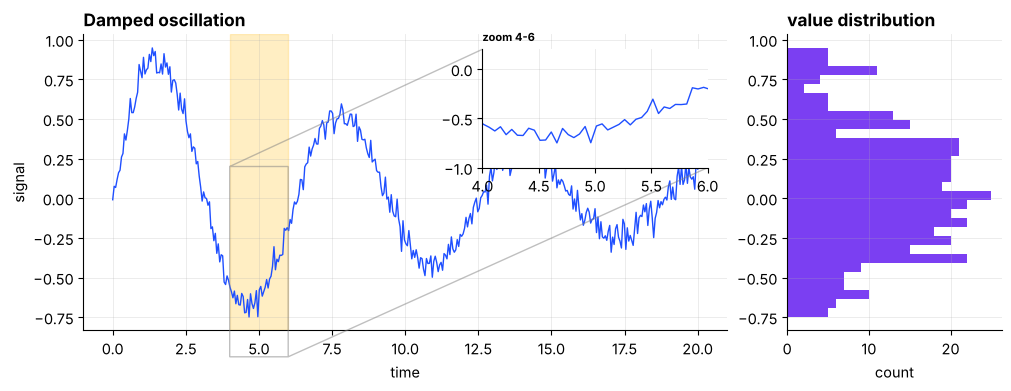

In [26]:
fig, axd = plt.subplot_mosaic([["main", "side"]], width_ratios=[3, 1], figsize=(10, 3.8), layout="constrained")
t = np.linspace(0, 20, 400)
sig = np.sin(t) * np.exp(-t / 12) + rng.normal(0, 0.05, t.size)
axd["main"].plot(t, sig, lw=1)
axd["main"].axvspan(4, 6, color="#ffd56b", alpha=0.4)
axd["main"].set(title="Damped oscillation", xlabel="time", ylabel="signal")
ins = axd["main"].inset_axes([0.62, 0.55, 0.35, 0.4])
ins.plot(t, sig, lw=1); ins.set_xlim(4, 6); ins.set_ylim(-1, 0.2)
ins.set_title("zoom 4-6", fontsize=8)
axd["main"].indicate_inset_zoom(ins, edgecolor="grey")
axd["side"].hist(sig, bins=30, orientation="horizontal", color="#7b3ff2")
axd["side"].set(title="value distribution", xlabel="count")
plt.show()

## 15.10 Getting the figure out: PNG, PDF and SVG · *Beginner*

**Save one figure in three formats**

In [27]:
fig, ax = plt.subplots(figsize=(3.5, 2.6))
ax.plot(months, sales_a, marker="o")
ax.set(title="Sales", ylabel="units")
fig.savefig("sales.png", dpi=300, bbox_inches="tight")
fig.savefig("sales.pdf", bbox_inches="tight")
fig.savefig("sales.svg", bbox_inches="tight")
plt.close(fig)
from pathlib import Path
for f in ["sales.png", "sales.pdf", "sales.svg"]:
    print(f, Path(f).stat().st_size // 1024, "KB")

sales.png 48 KB
sales.pdf 11 KB
sales.svg 22 KB


## Try it yourself

1. Draw a grouped bar chart of mean `charges` by `region` for smokers and non-smokers, using `insurance.csv`.
2. Make an ECDF of `bmi` for each sex on one axes. Which group has the higher median?
3. Save any chart from this chapter as a 600-dpi PNG and as a PDF, and compare the file sizes.

Worked solutions: [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 15*.